<a href="https://colab.research.google.com/github/Voruganti-Rishika/student-placement-prediction/blob/main/Student_Placement_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Placement Prediction using Machine Learning

## Objective
Predict whether a student is likely to get placed based on
academic performance, internships, projects, technical skills,
communication skills and other relevant features.


csv file link - "C:\Users\Dell\Downloads\indian_engineering_placement_2026.csv"

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("/content/indian_engineering_placement_2026.csv")
df

,Student_ID,Age,Gender,State,Branch,College_Tier,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,...,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Leadership_Experience,Extracurricular_Activities,Placement_Status,Package_LPA
0,ST00001,22,Male,Tamil Nadu,Mechanical,Tier-3,6.25,67.07,54,25,...,129,56.0,2,632,11,62,No,2,Not Placed,0.00
1,ST00002,21,Male,Uttar Pradesh,Mechanical,Tier-3,7.53,87.69,115,49,...,221,0.0,1,697,9,39,No,4,Not Placed,0.00
2,ST00003,23,Male,Jharkhand,IT,Tier-3,7.90,82.78,268,47,...,796,36.0,5,1850,41,55,No,1,Placed,6.87
3,ST00004,22,Female,Maharashtra,CSE,Tier-3,7.00,67.11,163,27,...,1077,47.0,2,1236,34,60,Yes,2,Placed,10.47
4,ST00005,19,Male,Maharashtra,AIML,Tier-2,6.23,78.93,221,24,...,442,42.0,4,1314,14,61,No,2,Placed,9.17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,ST14996,23,Female,Karnataka,CSE,Tier-1,7.35,74.32,307,46,...,460,57.0,4,1663,4,57,Yes,4,Placed,12.21
14996,ST14997,21,Male,Haryana,AIML,Tier-3,6.77,61.31,151,21,...,647,26.0,7,1826,19,32,No,1,Placed,6.71
14997,ST14998,19,Male,Delhi,CSE,Tier-2,8.09,83.10,204,56,...,573,21.0,3,1589,16,39,Yes,3,Not Placed,0.00
14998,ST14999,20,Female,Maharashtra,IT,Tier-2,6.75,61.01,198,50,...,351,43.0,3,1437,12,57,No,5,Placed,10.63


In [3]:
df.head()

,Student_ID,Age,Gender,State,Branch,College_Tier,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,...,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Leadership_Experience,Extracurricular_Activities,Placement_Status,Package_LPA
0,ST00001,22,Male,Tamil Nadu,Mechanical,Tier-3,6.25,67.07,54,25,...,129,56.0,2,632,11,62,No,2,Not Placed,0.00
1,ST00002,21,Male,Uttar Pradesh,Mechanical,Tier-3,7.53,87.69,115,49,...,221,0.0,1,697,9,39,No,4,Not Placed,0.00
2,ST00003,23,Male,Jharkhand,IT,Tier-3,7.90,82.78,268,47,...,796,36.0,5,1850,41,55,No,1,Placed,6.87
3,ST00004,22,Female,Maharashtra,CSE,Tier-3,7.00,67.11,163,27,...,1077,47.0,2,1236,34,60,Yes,2,Placed,10.47
4,ST00005,19,Male,Maharashtra,AIML,Tier-2,6.23,78.93,221,24,...,442,42.0,4,1314,14,61,No,2,Placed,9.17


In [4]:
df.shape

(15000, 25)

In [5]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'State', 'Branch', 'College_Tier',
       'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved',
       'Aptitude_Score', 'Communication_Score', 'Projects_Count',
       'Internships_Count', 'Certifications_Count',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'LinkedIn_Activity_Score', 'Hackathons_Participated',
       'Competitive_Programming_Rating', 'Study_Hours_Per_Week',
       'Soft_Skills_Score', 'Leadership_Experience',
       'Extracurricular_Activities', 'Placement_Status', 'Package_LPA'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      15000 non-null  object 
 1   Age                             15000 non-null  int64  
 2   Gender                          15000 non-null  object 
 3   State                           15000 non-null  object 
 4   Branch                          15000 non-null  object 
 5   College_Tier                    15000 non-null  object 
 6   CGPA                            15000 non-null  float64
 7   Attendance_Percentage           15000 non-null  float64
 8   DSA_Problems_Solved             15000 non-null  int64  
 9   Aptitude_Score                  15000 non-null  int64  
 10  Communication_Score             15000 non-null  int64  
 11  Projects_Count                  15000 non-null  int64  
 12  Internships_Count               

In [7]:
df.describe()

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Extracurricular_Activities,Package_LPA
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,14745.000000,15000.000000,14775.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,21.153400,7.477432,73.774239,181.760667,39.993400,53.912333,3.514600,1.201267,3.499200,82.736792,506.151000,30.124196,2.206333,1121.632800,17.986733,52.239600,2.285933,6.547623
std,1.536324,0.870838,7.516522,83.611775,14.400763,15.731021,2.004708,1.131979,2.014978,63.965529,321.159554,18.463372,1.567096,533.458634,8.395494,11.150848,1.577236,7.273714
min,18.000000,4.050000,50.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,57.000000,0.000000,0.000000,126.000000,0.000000,15.000000,0.000000,0.000000
25%,20.000000,6.890000,68.660000,123.000000,30.000000,43.000000,2.000000,0.000000,2.000000,44.000000,291.000000,16.000000,1.000000,679.000000,12.000000,45.000000,1.000000,0.000000
50%,21.000000,7.470000,73.720000,176.000000,40.000000,54.000000,3.000000,1.000000,3.000000,65.000000,421.000000,29.000000,2.000000,912.000000,18.000000,52.000000,2.000000,5.940000
75%,22.000000,8.060000,78.810000,225.000000,49.000000,64.000000,5.000000,2.000000,5.000000,100.000000,637.000000,43.000000,3.000000,1585.000000,24.000000,60.000000,3.000000,10.170000
max,25.000000,10.000000,100.000000,1199.000000,99.000000,100.000000,14.000000,5.000000,15.000000,968.000000,4891.000000,100.000000,10.000000,2500.000000,50.000000,93.000000,10.000000,49.990000


In [8]:
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
State,0
Branch,0
College_Tier,0
CGPA,0
Attendance_Percentage,0
DSA_Problems_Solved,0
Aptitude_Score,0


In [9]:
df.duplicated().sum()

np.int64(0)

CGPA                → student's academic performance

Internships         → number of internships

Projects            → number of projects

Coding_Skill        → coding ability

Communication       → communication score

Placed              → target

In [10]:
# Exploratory Data Analysis
df["Placement_Status"].value_counts()


,count
Placement_Status,
Placed,9770
Not Placed,5230


In [11]:
X = df.drop(
    ["Placement_Status", "Package_LPA", "Student_ID"],
    axis=1
)

y = df["Placement_Status"]

In [12]:
print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Age', 'Gender', 'State', 'Branch', 'College_Tier', 'CGPA',
       'Attendance_Percentage', 'DSA_Problems_Solved', 'Aptitude_Score',
       'Communication_Score', 'Projects_Count', 'Internships_Count',
       'Certifications_Count', 'Open_Source_Contributions',
       'GitHub_Contributions', 'LinkedIn_Activity_Score',
       'Hackathons_Participated', 'Competitive_Programming_Rating',
       'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Leadership_Experience',
       'Extracurricular_Activities'],
      dtype='object')

Target:
Placement_Status


In [13]:
y = y.map({
    "Not Placed": 0,
    "Placed": 1
})

In [14]:
y.value_counts()

,count
Placement_Status,
1,9770
0,5230


In [15]:
X.select_dtypes(include="object").columns

Index(['Gender', 'State', 'Branch', 'College_Tier', 'Leadership_Experience'], dtype='object')

In [16]:
X = pd.get_dummies(X, drop_first=True)

In [17]:
X.head()

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,...,Branch_CSE,Branch_Chemical,Branch_Civil,Branch_ECE,Branch_EEE,Branch_IT,Branch_Mechanical,College_Tier_Tier-2,College_Tier_Tier-3,Leadership_Experience_Yes
0,22,6.25,67.07,54,25,76,4,1,3,28.0,...,False,False,False,False,False,False,True,False,True,False
1,21,7.53,87.69,115,49,23,2,0,1,39.0,...,False,False,False,False,False,False,True,False,True,False
2,23,7.90,82.78,268,47,57,3,3,4,220.0,...,False,False,False,False,False,True,False,False,True,False
3,22,7.00,67.11,163,27,56,5,2,4,131.0,...,True,False,False,False,False,False,False,False,True,True
4,19,6.23,78.93,221,24,63,2,0,2,123.0,...,False,False,False,False,False,False,False,True,False,False


In [18]:
print(X.shape)

(15000, 48)


In [19]:
X.isnull().sum()

,0
Age,0
CGPA,0
Attendance_Percentage,0
DSA_Problems_Solved,0
Aptitude_Score,0
Communication_Score,0
Projects_Count,0
Internships_Count,0
Certifications_Count,0
Open_Source_Contributions,255


In [20]:
numeric_columns = X.select_dtypes(include="number").columns

X[numeric_columns] = X[numeric_columns].fillna(
    X[numeric_columns].median()
)

In [21]:
X = X.fillna(0)

In [22]:
X.isnull().sum().sum()

np.int64(0)

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12000, 48)
Testing data: (3000, 48)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train → fit_transform()

X_test  → transform()

In [27]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12000, 48)
X_test: (3000, 48)
y_train: (12000,)
y_test: (3000,)


In [28]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Missing values in X: 0
Missing values in y: 0


Data

 ↓

Removed ID + leakage column

 ↓

Separated X and y

 ↓

Encoded categorical variables

 ↓

Handled missing values

 ↓

Train/Test split

 ↓

Feature scaling

 ↓

READY FOR MACHINE LEARNING ✅

In [29]:
# Logistic Regression
X_train_scaled
X_test_scaled

array([[ 0.55447597,  0.20061897, -0.16823866, ..., -0.90895878,
         1.22751343,  1.78358758],
       [-0.09580859, -1.35224106, -1.07690888, ..., -0.90895878,
         1.22751343,  1.78358758],
       [-1.39637772, -1.9963904 , -2.13393342, ...,  1.1001599 ,
        -0.81465504, -0.56066773],
       ...,
       [-1.39637772,  1.02881099,  1.05965827, ..., -0.90895878,
         1.22751343, -0.56066773],
       [-2.04666228,  0.56870431,  0.05561742, ..., -0.90895878,
        -0.81465504, -0.56066773],
       [ 0.55447597, -0.00642903,  1.06230746, ..., -0.90895878,
         1.22751343, -0.56066773]])

In [30]:
# Decision Tree / Random Forest
X_train
X_test

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,...,Branch_CSE,Branch_Chemical,Branch_Civil,Branch_ECE,Branch_EEE,Branch_IT,Branch_Mechanical,College_Tier_Tier-2,College_Tier_Tier-3,Leadership_Experience_Yes
4233,22,7.65,72.48,205,65,52,6,2,8,67.0,...,False,False,False,False,False,True,False,False,True,True
4416,21,6.30,65.62,43,68,45,3,1,4,91.0,...,False,False,False,True,False,False,False,False,True,True
8674,19,5.74,57.64,214,42,81,3,1,2,65.0,...,False,False,False,True,False,False,False,True,False,False
11670,21,5.72,69.42,201,27,83,3,0,3,84.0,...,True,False,False,False,False,False,False,True,False,True
9093,20,9.24,76.82,256,66,83,6,2,6,78.0,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12972,23,8.92,79.01,177,30,29,4,2,3,45.0,...,False,False,False,False,True,False,False,False,True,False
712,22,7.64,73.50,86,35,52,1,1,0,20.0,...,False,False,False,False,False,False,True,False,True,False
5137,19,8.37,81.75,177,54,53,7,2,4,50.0,...,False,False,False,False,False,True,False,False,True,False
10126,18,7.97,74.17,361,40,63,4,3,6,91.0,...,False,False,False,False,False,True,False,False,False,False


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [32]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

X_train_scaled + y_train

          ↓
   Logistic Regression

          ↓
     Learned patterns

In [33]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [34]:
print(y_pred_lr[:20])

[1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1]


0 → Not Placed

1 → Placed

In [35]:
from sklearn.metrics import accuracy_score

In [36]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

Logistic Regression Accuracy: 0.806


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.74      0.69      0.71      1046
           1       0.84      0.87      0.85      1954

    accuracy                           0.81      3000
   macro avg       0.79      0.78      0.78      3000
weighted avg       0.80      0.81      0.80      3000



Accuracy  → Overall correctness

Precision → How reliable positive predictions are

Recall    → How many actual positives we found

F1        → Balance of precision and recall

In [38]:
from sklearn.metrics import confusion_matrix

In [39]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print(cm_lr)

[[ 724  322]
 [ 260 1694]]


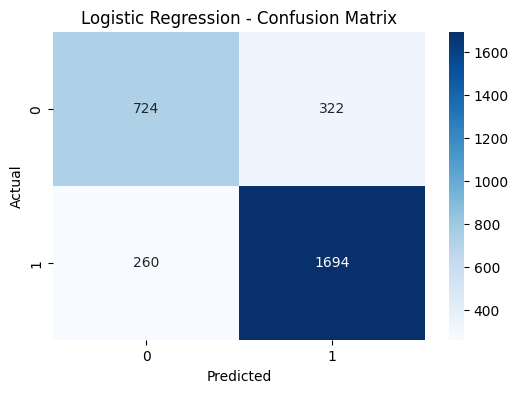

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

#DECISION TREE

                 Predicted
                 0       1

Actual 0         TN      FP

Actual 1        FN      TP

In [41]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [42]:
X_train

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,...,Branch_CSE,Branch_Chemical,Branch_Civil,Branch_ECE,Branch_EEE,Branch_IT,Branch_Mechanical,College_Tier_Tier-2,College_Tier_Tier-3,Leadership_Experience_Yes
1627,20,7.42,85.01,261,0,55,5,2,4,84.0,...,True,False,False,False,False,False,False,False,False,True
6982,20,7.20,74.56,113,29,50,5,3,1,48.0,...,False,True,False,False,False,False,False,True,False,False
6625,23,6.19,62.18,186,44,47,6,0,5,75.0,...,True,False,False,False,False,False,False,True,False,False
7586,20,6.82,72.02,218,25,90,7,2,6,87.0,...,False,False,False,False,False,False,False,False,False,True
1590,20,6.62,69.67,168,36,42,6,1,1,52.0,...,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1763,19,6.72,68.24,83,40,68,1,1,2,67.0,...,False,False,False,False,False,False,True,False,True,False
8589,22,8.24,81.55,201,40,60,5,2,4,53.0,...,False,False,False,False,False,False,True,True,False,True
6487,22,7.31,55.93,80,44,50,1,1,5,29.0,...,False,False,False,False,True,False,False,True,False,False
955,23,8.95,71.18,141,25,84,1,1,4,59.0,...,False,True,False,False,False,False,False,True,False,False


In [43]:
X_train_scaled

array([[-0.74609316, -0.06394237,  1.49147532, ..., -0.90895878,
        -0.81465504,  1.78358758],
       [-0.74609316, -0.31700104,  0.10727651, ...,  1.1001599 ,
        -0.81465504, -0.56066773],
       [ 1.20476053, -1.47877039, -1.53256858, ...,  1.1001599 ,
        -0.81465504, -0.56066773],
       ...,
       [ 0.55447597, -0.1904717 , -2.36043868, ...,  1.1001599 ,
        -0.81465504, -0.56066773],
       [ 1.20476053,  1.69596567, -0.34043564, ...,  1.1001599 ,
        -0.81465504, -0.56066773],
       [-0.09580859, -0.69658904, -3.14592183, ..., -0.90895878,
         1.22751343, -0.56066773]])

In [44]:
y_pred_dt = dt_model.predict(X_test)

In [45]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.7126666666666667


In [46]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.59      0.58      0.58      1046
           1       0.78      0.78      0.78      1954

    accuracy                           0.71      3000
   macro avg       0.68      0.68      0.68      3000
weighted avg       0.71      0.71      0.71      3000



#RANDOM FOREST

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Tree 1

Tree 2

Tree

...
Tree 100

   ↓

Combine their predictions

   ↓

Final prediction

In [48]:
y_pred_rf = rf_model.predict(X_test)

In [49]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.7923333333333333


In [50]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.72      0.66      0.69      1046
           1       0.83      0.86      0.84      1954

    accuracy                           0.79      3000
   macro avg       0.77      0.76      0.77      3000
weighted avg       0.79      0.79      0.79      3000



In [51]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.806000
1,Decision Tree,0.712667
2,Random Forest,0.792333


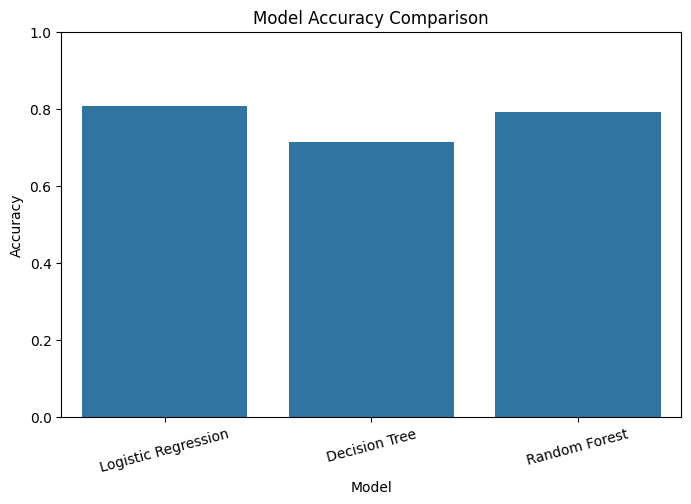

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=results
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=15)

plt.show()

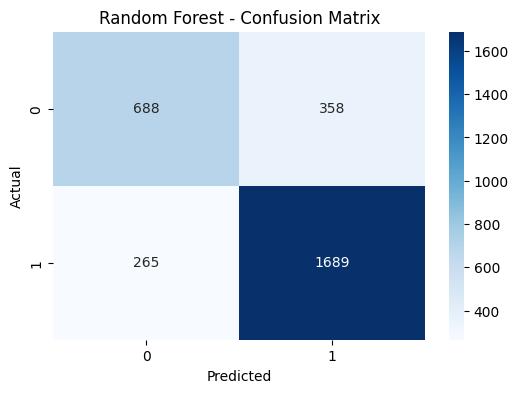

In [53]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [54]:
print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.72      0.66      0.69      1046
           1       0.83      0.86      0.84      1954

    accuracy                           0.79      3000
   macro avg       0.77      0.76      0.77      3000
weighted avg       0.79      0.79      0.79      3000



In [55]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
3,DSA_Problems_Solved,0.107275
13,Competitive_Programming_Rating,0.081473
1,CGPA,0.076815
10,GitHub_Contributions,0.068055
46,College_Tier_Tier-3,0.056808
9,Open_Source_Contributions,0.055755
4,Aptitude_Score,0.047896
5,Communication_Score,0.046632
2,Attendance_Percentage,0.044779
15,Soft_Skills_Score,0.041229


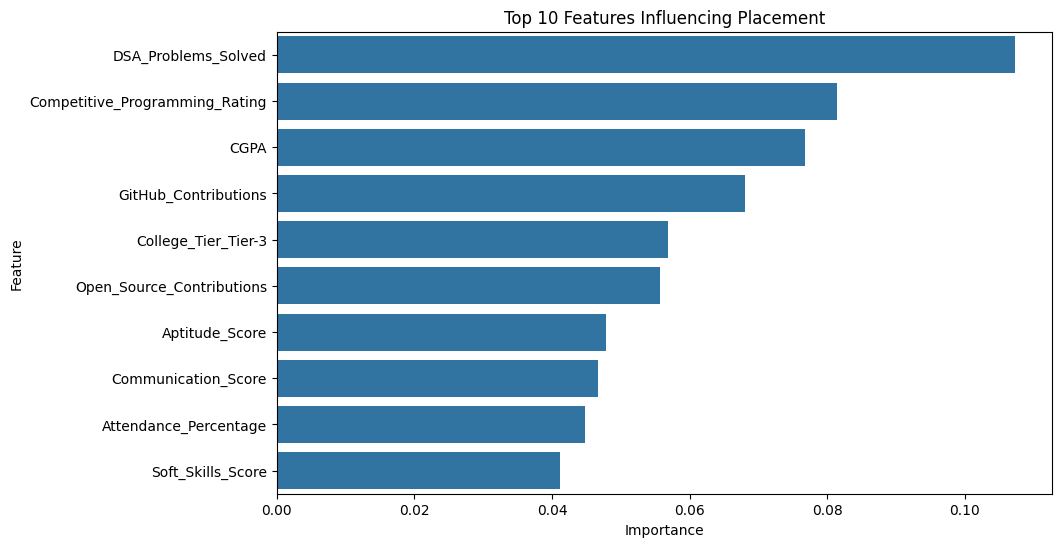

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance.head(10)
)

plt.title("Top 10 Features Influencing Placement")

plt.show()

In [57]:
probabilities = rf_model.predict_proba(X_test)

In [58]:
print(probabilities[:5])

[[0.21 0.79]
 [0.78 0.22]
 [0.45 0.55]
 [0.24 0.76]
 [0.03 0.97]]


Column 0 → Probability of Not Placed

Column 1 → Probability of Placed

In [59]:
probabilities[:, 1]

array([0.79, 0.22, 0.55, ..., 0.84, 1.  , 0.62])

In [60]:
sample_student = X_test.iloc[[0]]

In [61]:
prediction = rf_model.predict(sample_student)

print(prediction)

[1]


In [62]:
probability = rf_model.predict_proba(sample_student)

print(probability)

[[0.21 0.79]]


In [63]:
placement_probability = probability[0][1] * 100

print(
    f"Placement probability: {placement_probability:.2f}%"
)

Placement probability: 79.00%


✅ Logistic Regression

        ↓

   Predictions

        ↓

   Evaluation


✅ Decision Tree

        ↓

   Predictions

        ↓

   Evaluation


✅ Random Forest

        ↓
   Predictions

        ↓

   Evaluation


✅ Model comparison

✅ Confusion matrix

✅ Feature importance

✅ Placement probability

Dataset

   ↓

Data Cleaning

   ↓

EDA

   ↓

Encoding

   ↓

Train/Test Split

   ↓
Scaling

   ↓

Logistic Regression

   ↓

Decision Tree

   ↓

Random Forest

   ↓

Model Evaluation

   ↓
   
Feature Importance

Trained Model

     ↓

Save Model

     ↓

Load Model later

     ↓

Give new student's data

     ↓

Prediction

     ↓

Placement probability


In [64]:
results

,Model,Accuracy
0,Logistic Regression,0.806000
1,Decision Tree,0.712667
2,Random Forest,0.792333


In [65]:
final_model = rf_model

In [66]:
final_model = lr_model

In [67]:
import joblib

In [68]:
joblib.dump(final_model, "placement_model.pkl")

['placement_model.pkl']

In [69]:
scaler = StandardScaler()

In [70]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [71]:
feature_names = X_train.columns.tolist()

joblib.dump(feature_names, "feature_names.pkl")

['feature_names.pkl']

we have

placement_model.pkl

scaler.pkl

feature_names.pkl


In [72]:
loaded_model = joblib.load("placement_model.pkl")

In [73]:
loaded_scaler = joblib.load("scaler.pkl")

In [74]:
loaded_features = joblib.load("feature_names.pkl")

In [75]:
print(type(loaded_model))
print(len(loaded_features))

<class 'sklearn.linear_model._logistic.LogisticRegression'>
48


In [76]:
sample_student = X_test.iloc[[0]]

In [77]:
prediction = loaded_model.predict(sample_student)

print(prediction)

[1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [78]:
probability = loaded_model.predict_proba(sample_student)

print(probability)

[[0. 1.]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [79]:
placement_probability = probability[0][1] * 100

print(f"Placement Probability: {placement_probability:.2f}%")

Placement Probability: 100.00%


In [80]:
def predict_placement(student_data):
    prediction = loaded_model.predict(student_data)[0]

    probability = loaded_model.predict_proba(student_data)[0][1]

    if prediction == 1:
        result = "Placed"
    else:
        result = "Not Placed"

    return result, probability

In [81]:
result, probability = predict_placement(sample_student)

print("Prediction:", result)
print(f"Probability: {probability * 100:.2f}%")

Prediction: Placed
Probability: 100.00%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [82]:
X_train.columns

Index(['Age', 'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved',
       'Aptitude_Score', 'Communication_Score', 'Projects_Count',
       'Internships_Count', 'Certifications_Count',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'LinkedIn_Activity_Score', 'Hackathons_Participated',
       'Competitive_Programming_Rating', 'Study_Hours_Per_Week',
       'Soft_Skills_Score', 'Extracurricular_Activities', 'Gender_Male',
       'Gender_Other', 'State_Assam', 'State_Bihar', 'State_Chhattisgarh',
       'State_Delhi', 'State_Gujarat', 'State_Haryana', 'State_Jharkhand',
       'State_Karnataka', 'State_Kerala', 'State_Madhya Pradesh',
       'State_Maharashtra', 'State_Odisha', 'State_Punjab', 'State_Rajasthan',
       'State_Tamil Nadu', 'State_Telangana', 'State_Uttar Pradesh',
       'State_Uttarakhand', 'State_West Bengal', 'Branch_CSE',
       'Branch_Chemical', 'Branch_Civil', 'Branch_ECE', 'Branch_EEE',
       'Branch_IT', 'Branch_Mechanical', 'College_Tier_T

In [83]:
print(X_train.columns.tolist())

['Age', 'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved', 'Aptitude_Score', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'Certifications_Count', 'Open_Source_Contributions', 'GitHub_Contributions', 'LinkedIn_Activity_Score', 'Hackathons_Participated', 'Competitive_Programming_Rating', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Extracurricular_Activities', 'Gender_Male', 'Gender_Other', 'State_Assam', 'State_Bihar', 'State_Chhattisgarh', 'State_Delhi', 'State_Gujarat', 'State_Haryana', 'State_Jharkhand', 'State_Karnataka', 'State_Kerala', 'State_Madhya Pradesh', 'State_Maharashtra', 'State_Odisha', 'State_Punjab', 'State_Rajasthan', 'State_Tamil Nadu', 'State_Telangana', 'State_Uttar Pradesh', 'State_Uttarakhand', 'State_West Bengal', 'Branch_CSE', 'Branch_Chemical', 'Branch_Civil', 'Branch_ECE', 'Branch_EEE', 'Branch_IT', 'Branch_Mechanical', 'College_Tier_Tier-2', 'College_Tier_Tier-3', 'Leadership_Experience_Yes']


In [84]:
feature_names

['Age',
 'CGPA',
 'Attendance_Percentage',
 'DSA_Problems_Solved',
 'Aptitude_Score',
 'Communication_Score',
 'Projects_Count',
 'Internships_Count',
 'Certifications_Count',
 'Open_Source_Contributions',
 'GitHub_Contributions',
 'LinkedIn_Activity_Score',
 'Hackathons_Participated',
 'Competitive_Programming_Rating',
 'Study_Hours_Per_Week',
 'Soft_Skills_Score',
 'Extracurricular_Activities',
 'Gender_Male',
 'Gender_Other',
 'State_Assam',
 'State_Bihar',
 'State_Chhattisgarh',
 'State_Delhi',
 'State_Gujarat',
 'State_Haryana',
 'State_Jharkhand',
 'State_Karnataka',
 'State_Kerala',
 'State_Madhya Pradesh',
 'State_Maharashtra',
 'State_Odisha',
 'State_Punjab',
 'State_Rajasthan',
 'State_Tamil Nadu',
 'State_Telangana',
 'State_Uttar Pradesh',
 'State_Uttarakhand',
 'State_West Bengal',
 'Branch_CSE',
 'Branch_Chemical',
 'Branch_Civil',
 'Branch_ECE',
 'Branch_EEE',
 'Branch_IT',
 'Branch_Mechanical',
 'College_Tier_Tier-2',
 'College_Tier_Tier-3',
 'Leadership_Experience_Yes

In [85]:
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'State', 'Branch', 'College_Tier', 'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved', 'Aptitude_Score', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'Certifications_Count', 'Open_Source_Contributions', 'GitHub_Contributions', 'LinkedIn_Activity_Score', 'Hackathons_Participated', 'Competitive_Programming_Rating', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Leadership_Experience', 'Extracurricular_Activities', 'Placement_Status', 'Package_LPA']


In [86]:
print(X.columns.tolist())

['Age', 'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved', 'Aptitude_Score', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'Certifications_Count', 'Open_Source_Contributions', 'GitHub_Contributions', 'LinkedIn_Activity_Score', 'Hackathons_Participated', 'Competitive_Programming_Rating', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Extracurricular_Activities', 'Gender_Male', 'Gender_Other', 'State_Assam', 'State_Bihar', 'State_Chhattisgarh', 'State_Delhi', 'State_Gujarat', 'State_Haryana', 'State_Jharkhand', 'State_Karnataka', 'State_Kerala', 'State_Madhya Pradesh', 'State_Maharashtra', 'State_Odisha', 'State_Punjab', 'State_Rajasthan', 'State_Tamil Nadu', 'State_Telangana', 'State_Uttar Pradesh', 'State_Uttarakhand', 'State_West Bengal', 'Branch_CSE', 'Branch_Chemical', 'Branch_Civil', 'Branch_ECE', 'Branch_EEE', 'Branch_IT', 'Branch_Mechanical', 'College_Tier_Tier-2', 'College_Tier_Tier-3', 'Leadership_Experience_Yes']


In [87]:
new_student = X_test.iloc[[5]]

In [88]:
prediction = loaded_model.predict(new_student)[0]

probability = loaded_model.predict_proba(new_student)[0][1]

print("Prediction:", "Placed" if prediction == 1 else "Not Placed")
print(f"Probability: {probability * 100:.2f}%")

Prediction: Placed
Probability: 100.00%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


started with:

CSV Dataset

     ↓

Cleaning

     ↓

EDA

     ↓

Preprocessing

     ↓

Train ML Models

     ↓

Compare Models


now

Best Model

     ↓

placement_model.pkl

     ↓

Saved Scaler

     ↓
scaler.pkl

     ↓

Saved Features

     ↓
     
feature_names.pkl

In [114]:
!pip install streamlit

In [115]:
%%writefile app.py

Writing app.py


In [119]:
!ls

app.py		   indian_engineering_placement_2026.csv  sample_data
feature_names.pkl  placement_model.pkl			  scaler.pkl


In [120]:
import pandas as pd
import joblib

# Load the original dataset if df is not already available
# df = pd.read_csv("/content/indian_engineering_placement_2026.csv")

categorical_columns = [
    "Gender",
    "State",
    "Branch",
    "College_Tier",
    "Leadership_Experience"
]

category_levels = {
    col: sorted(df[col].dropna().unique().tolist())
    for col in categorical_columns
}

joblib.dump(category_levels, "category_levels.pkl")

print("category_levels.pkl created successfully!")

category_levels.pkl created successfully!


In [121]:
!ls

app.py		     indian_engineering_placement_2026.csv  scaler.pkl
category_levels.pkl  placement_model.pkl
feature_names.pkl    sample_data


In [122]:
!streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [123]:
!cat /content/streamlit.log



2026-10-11 09:58:32.224 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.201.164.210:8501



In [124]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [125]:
!ls

app.py		     indian_engineering_placement_2026.csv  scaler.pkl
category_levels.pkl  placement_model.pkl		    streamlit.log
feature_names.pkl    sample_data


In [126]:
%%writefile requirements.txt
streamlit
pandas
scikit-learn
joblib

Writing requirements.txt


In [127]:
%%writefile README.md
# Student Placement Prediction

## About the Project
This machine learning project predicts whether an engineering student
may be placed based on academic performance, technical skills,
projects, internships, and other student details.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- Streamlit
- Joblib

## Machine Learning Models
- Logistic Regression
- Decision Tree
- Random Forest

## How to Run Locally

1. Install Python.
2. Install the required libraries:
   pip install -r requirements.txt
3. Run the application:
   streamlit run app.py

## Disclaimer
This is an educational project. Predictions are estimates, not
guarantees of actual placement outcomes. Results depend on the
quality and representativeness of the training data.

Writing README.md


In [128]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [129]:
from google.colab import files

for filename in [
    "placement_model.pkl",
    "feature_names.pkl",
    "category_levels.pkl",
    "requirements.txt",
    "README.md"
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>